<a href="https://colab.research.google.com/github/BeeMugo9/BeeMugo9/blob/main/Financial_Risk_Assessment_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Problem Statement:
Businesses or companies can fall prey to default if they are not able to keep up their debt obligations. Defaults will lead to a lower credit rating for the company which in turn reduces its chances of getting credit in the future and may have to pay higher interest on existing debts as well as any new obligations. From an investor's point of view, he would want to invest in a company if it is capable of handling its financial obligations, can grow quickly, and is able to manage the growth scale.

A balance sheet is a financial statement of a company that provides a snapshot of what a company owns, owes, and the amount invested by the shareholders. Thus, it is an important tool that helps evaluate the performance of a business. Data that is available includes information from the financial statement of the companies for the previous year.

Dependent variable - No need to create any new variable, as the 'Default' variable is already provided in the dataset, which can be considered as the dependent variable.

Test Train Split - Split the data into train and test datasets in the ratio of 67:33 and use a random state of 42 (random_state=42). Model building is to be done on the train dataset and model validation is to be done on the test dataset.

Dataset: Credit Risk Dataset- CompData

In [1]:
# 1) Core libraries
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
    precision_score, recall_score, f1_score, accuracy_score
)

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import RandomForestClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor


In [7]:
# upload files
from google.colab import files
uploaded = files.upload()


Saving CompData-1.xlsx to CompData-1.xlsx


In [13]:
df = pd.read_excel('CompData-1.xlsx')  # read data

##2. Basic Checks (Target, Duplicates, Types)

In [15]:
# 3) Basic checks
print(df.columns)
print(df.dtypes)

# Target variable check
TARGET = "Default"
print(df[TARGET].value_counts(dropna=False))
print(df[TARGET].value_counts(normalize=True, dropna=False))

# Duplicates
dup_count = df.duplicated().sum()
print("Duplicate rows:", dup_count)


Index(['Co_Code', 'Co_Name', '_Operating_Expense_Rate',
       '_Research_and_development_expense_rate', '_Cash_flow_rate',
       '_Interest_bearing_debt_interest_rate', '_Tax_rate_A',
       '_Cash_Flow_Per_Share', '_Per_Share_Net_profit_before_tax_Yuan_',
       '_Realized_Sales_Gross_Profit_Growth_Rate',
       '_Operating_Profit_Growth_Rate', '_Continuous_Net_Profit_Growth_Rate',
       '_Total_Asset_Growth_Rate', '_Net_Value_Growth_Rate',
       '_Total_Asset_Return_Growth_Rate_Ratio', '_Cash_Reinvestment_perc',
       '_Current_Ratio', '_Quick_Ratio', '_Interest_Expense_Ratio',
       '_Total_debt_to_Total_net_worth', '_Long_term_fund_suitability_ratio_A',
       '_Net_profit_before_tax_to_Paid_in_capital', '_Total_Asset_Turnover',
       '_Accounts_Receivable_Turnover', '_Average_Collection_Days',
       '_Inventory_Turnover_Rate_times', '_Fixed_Assets_Turnover_Frequency',
       '_Net_Worth_Turnover_Rate_times', '_Operating_profit_per_person',
       '_Allocation_rate_per_pers

## 3. Missing Value Treatment

In [17]:
# 4) Missingness report
missing = df.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
print("Columns with missing values:\n", missing)



Columns with missing values:
 _Cash_Flow_Per_Share                    0.081147
_Cash_to_Total_Assets                   0.046647
_Total_debt_to_Total_net_worth          0.010204
_Current_Liability_to_Current_Assets    0.006803
dtype: float64


In [18]:
# missing counts
missing_counts = df.isna().sum().sort_values(ascending=False)
print(missing_counts[missing_counts > 0])

_Cash_Flow_Per_Share                    167
_Cash_to_Total_Assets                    96
_Total_debt_to_Total_net_worth           21
_Current_Liability_to_Current_Assets     14
dtype: int64


The dataset contained missing values in four financial ratio variables. The proportion of missing data ranged from 0.68% to 8.11%, which is below the commonly accepted threshold of 10%. Therefore, deletion of observations was not warranted.

Since the variables represent financial ratios that are typically skewed and prone to outliers, median imputation was applied to replace missing values. This approach ensures robustness and preserves the overall distribution of the data.

In [19]:
# List of columns with missing values
missing_cols = [
    "_Cash_Flow_Per_Share",
    "_Cash_to_Total_Assets",
    "_Total_debt_to_Total_net_worth",
    "_Current_Liability_to_Current_Assets"
]

# Median imputation
for col in missing_cols:
    median_value = df[col].median()
    df[col] = df[col].fillna(median_value)

# Check again
df[missing_cols].isna().sum()


,0
_Cash_Flow_Per_Share,0
_Cash_to_Total_Assets,0
_Total_debt_to_Total_net_worth,0
_Current_Liability_to_Current_Assets,0


## 4. Outlier Treatment

In [20]:

# 5) Identify numeric/categorical columns
num_cols = df.select_dtypes(include=["number"]).columns.tolist()
cat_cols = [c for c in df.columns if c not in num_cols]

# Remove target from predictors lists
if TARGET in num_cols: num_cols.remove(TARGET)
if TARGET in cat_cols: cat_cols.remove(TARGET)

print("Numeric columns:", len(num_cols))
print("Categorical columns:", len(cat_cols))


Numeric columns: 56
Categorical columns: 1


In [21]:
#IQR-based capping (winsorization) for numeric outliers
def iqr_cap_series(s: pd.Series, k: float = 1.5) -> pd.Series:
    """Cap outliers using IQR method (winsorization)."""
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - k * iqr
    upper = q3 + k * iqr
    return s.clip(lower=lower, upper=upper)

# 6) Apply capping to numeric predictors (withut touching TARGET)
df_out = df.copy()
for c in num_cols:
    df_out[c] = iqr_cap_series(df_out[c], k=1.5)

df = df_out


If one company shows a crazy extreme ratio due to reporting error or rare event, we cap it to a reasonable boundary so the model doesn’t get ‘pulled’ by that one row.

## 5. EDA: Univariate & Bivariate

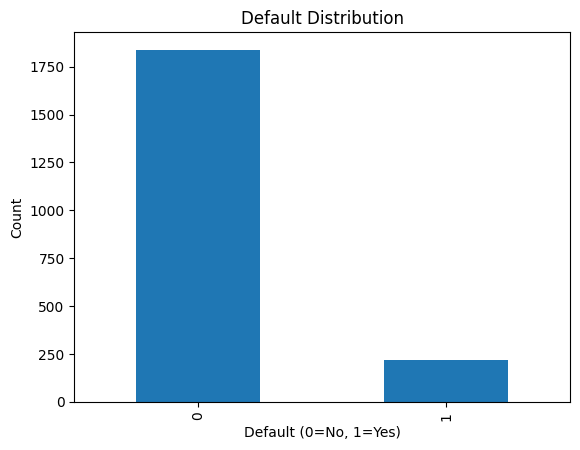

,count,mean,std,min,25%,50%,75%,max,missing
Co_Code,2058.0,1.595707e+04,1.822032e+04,4.000000,3674.000000,6240.000000,2.428075e+04,5.519088e+04,0
_Operating_Expense_Rate,2058.0,2.052389e+09,3.252624e+09,0.000100,0.000158,0.000333,4.110000e+09,9.980000e+09,0
_Research_and_development_expense_rate,2058.0,9.319190e+08,1.444850e+09,0.000000,0.000000,0.000199,1.550000e+09,3.875000e+09,0
_Cash_flow_rate,2058.0,4.644147e-01,7.456748e-03,0.448144,0.460099,0.463445,4.680691e-01,4.800240e-01,0
_Interest_bearing_debt_interest_rate,2058.0,4.842165e-04,2.963605e-04,0.000000,0.000276,0.000454,6.630660e-04,1.243623e-03,0
_Tax_rate_A,2058.0,1.104916e-01,1.349074e-01,0.000000,0.000000,0.037099,2.161909e-01,5.404773e-01,0
_Cash_Flow_Per_Share,2058.0,3.204623e-01,9.041348e-03,0.301182,0.315705,0.320648,3.253873e-01,3.399103e-01,0
_Per_Share_Net_profit_before_tax_Yuan_,2058.0,1.763915e-01,1.804076e-02,0.137682,0.166604,0.175642,1.858854e-01,2.148076e-01,0
_Realized_Sales_Gross_Profit_Growth_Rate,2058.0,2.210970e-02,9.341527e-05,0.021918,0.022058,0.022100,2.215200e-02,2.229253e-02,0
_Operating_Profit_Growth_Rate,2058.0,8.480460e-01,1.429283e-04,0.847763,0.847974,0.848039,8.481147e-01,8.483259e-01,0


In [22]:
# 7) Univariate for target
ax = df[TARGET].value_counts().plot(kind="bar")
plt.title("Default Distribution")
plt.xlabel("Default (0=No, 1=Yes)")
plt.ylabel("Count")
plt.show()

# 8) Univariate summary for numeric columns
desc = df[num_cols].describe().T
desc["missing"] = df[num_cols].isna().sum()
desc.head(10)


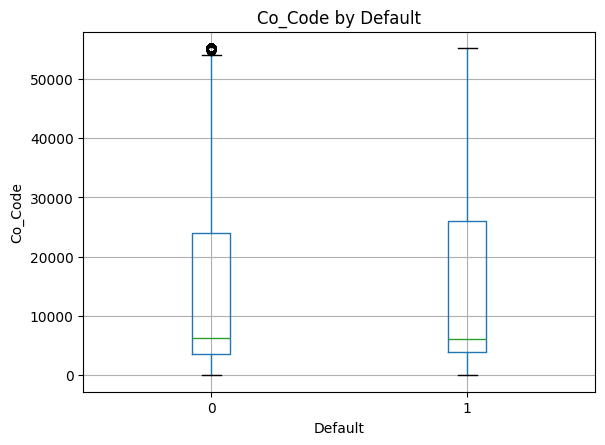

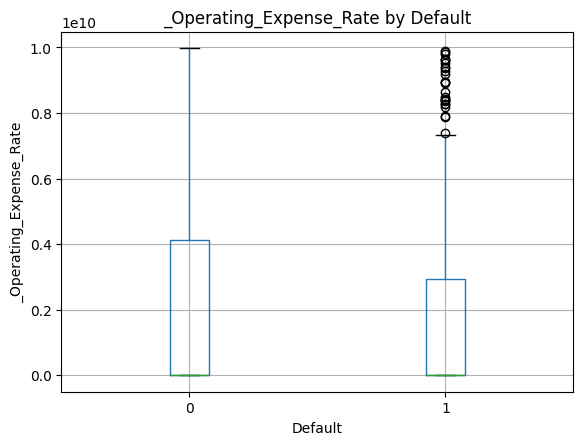

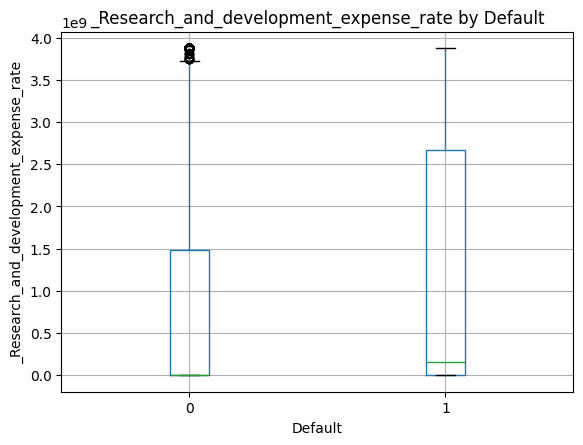

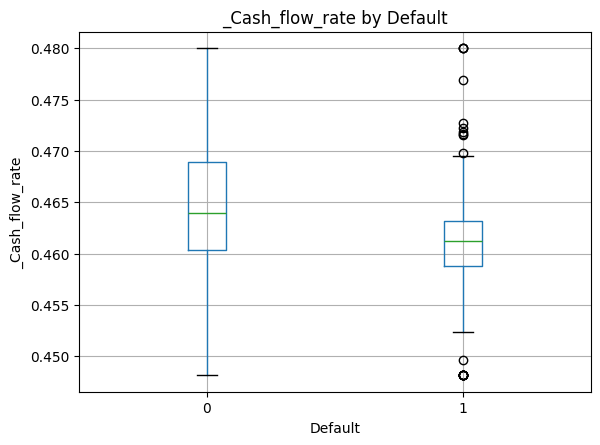

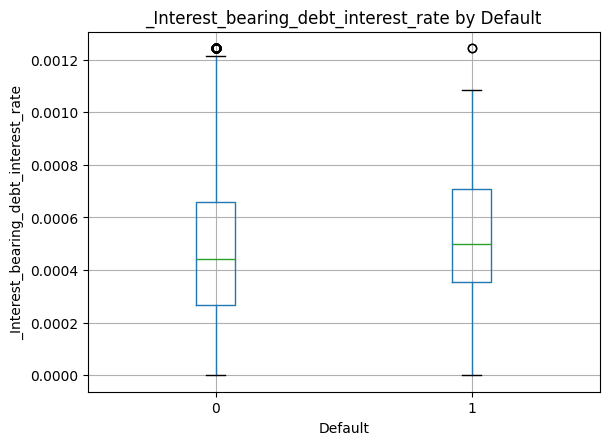

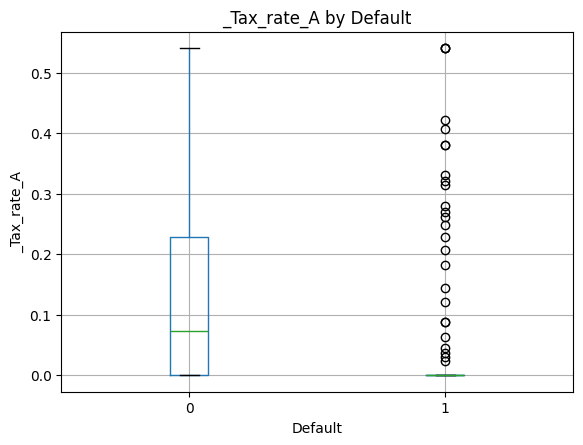

In [25]:
#Bivariate: numeric vs Default (boxplots) and correlation
# 9) Boxplots for a few numeric variables vs Default
sample_cols = num_cols[:6]  # change to the key variables later
for c in sample_cols:
    df.boxplot(column=c, by=TARGET)
    plt.title(f"{c} by Default")
    plt.suptitle("")
    plt.xlabel("Default")
    plt.ylabel(c)
    plt.show()



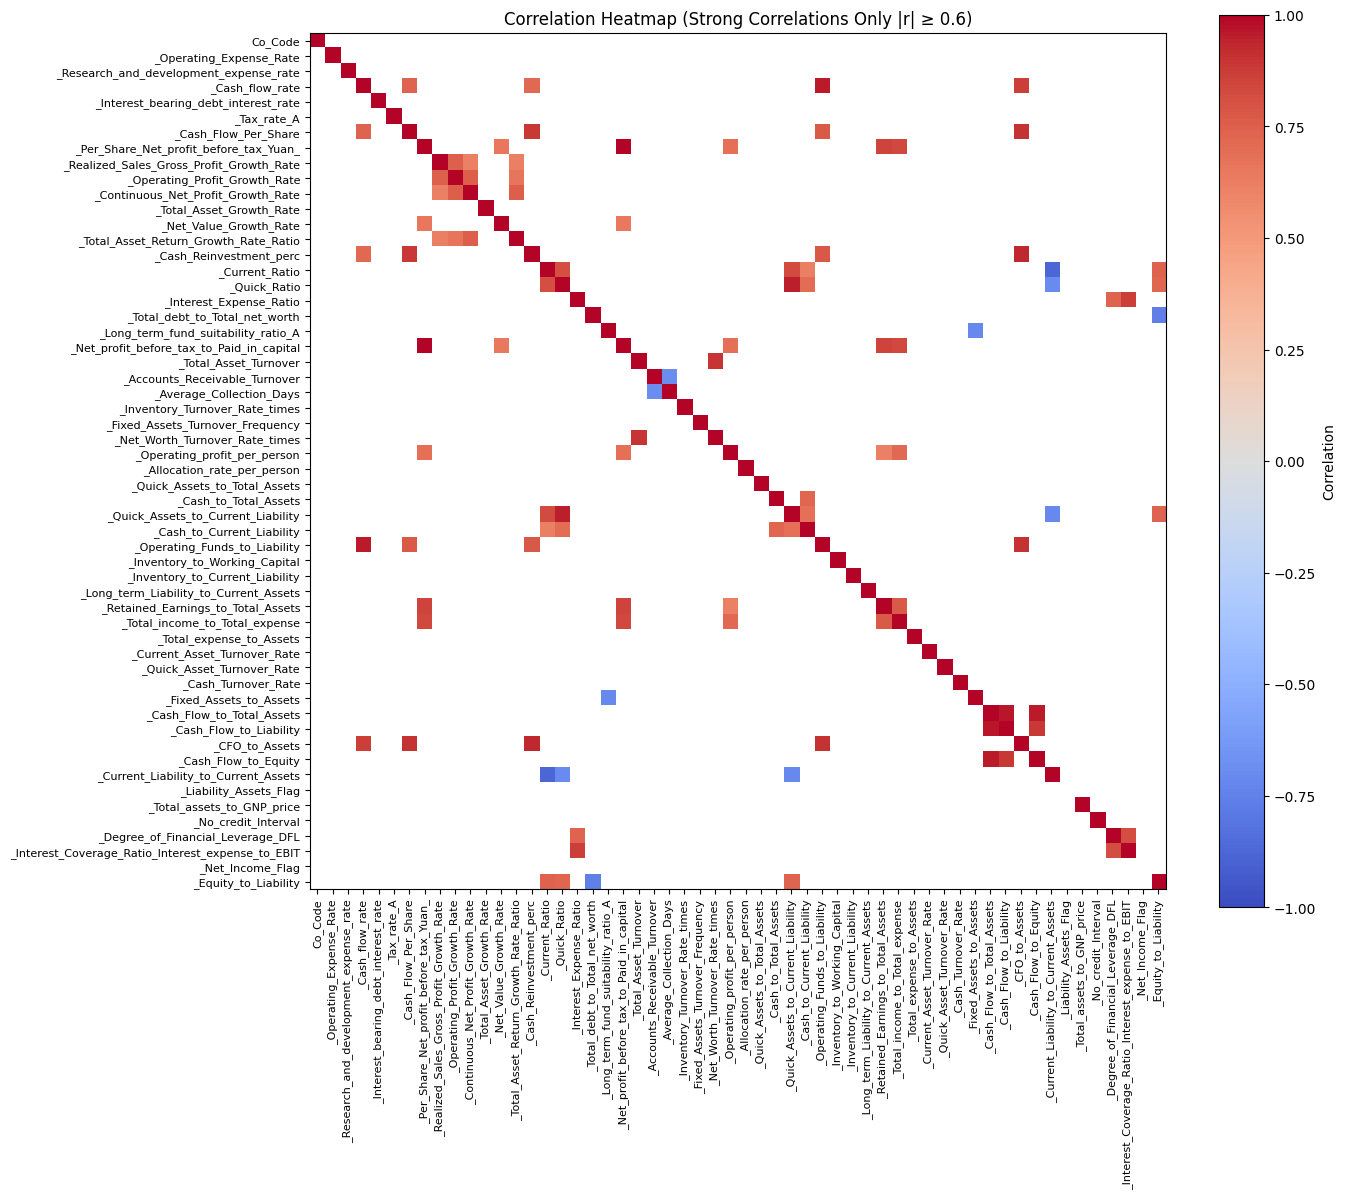

In [24]:
# 10) Correlation heatmap (numeric only)
corr = df[num_cols].corr()

# Mask weak correlations
threshold = 0.6
strong_corr = corr.where(abs(corr) >= threshold)

plt.figure(figsize=(14, 12))
plt.imshow(strong_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")

plt.title("Correlation Heatmap (Strong Correlations Only |r| ≥ 0.6)")

plt.xticks(range(len(strong_corr.columns)), strong_corr.columns, rotation=90, fontsize=8)
plt.yticks(range(len(strong_corr.columns)), strong_corr.columns, fontsize=8)

plt.tight_layout()
plt.show()


In [26]:
#Quick “significance screen”
#We check which financial metrics look noticeably different between companies that defaulted vs those that didn’t.
# 11) Simple screen: difference in means by Default (numeric)
group_means = df.groupby(TARGET)[num_cols].mean().T
group_means["diff_(1-0)"] = group_means[1] - group_means[0]
group_means.sort_values("diff_(1-0)", ascending=False).head(15)


Default,0,1,diff_(1-0)
_Research_and_development_expense_rate,9.001644e+08,1.197214e+09,2.970497e+08
_Inventory_Turnover_Rate_times,2.016287e+09,2.118543e+09,1.022556e+08
_Quick_Asset_Turnover_Rate,2.563500e+09,2.640836e+09,7.733587e+07
Co_Code,1.580673e+04,1.721315e+04,1.406421e+03
_Fixed_Assets_to_Assets,2.662046e-01,3.269129e-01,6.070828e-02
_Current_Liability_to_Current_Assets,3.273785e-02,5.074724e-02,1.800939e-02
_Total_expense_to_Assets,2.559629e-02,3.690629e-02,1.131000e-02
_Total_debt_to_Total_net_worth,8.494625e-03,1.630999e-02,7.815366e-03
_Allocation_rate_per_person,1.691809e-02,2.130933e-02,4.391239e-03
_Long_term_Liability_to_Current_Assets,6.404372e-03,1.015236e-02,3.747985e-03


## 6. Train/Test Split

In [27]:
# 12) Train/test split
#We learn patterns from 67% of companies, then test the model on the remaining 33% it never saw.
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.33,
    random_state=42,
    stratify=y  # recommended for default problems
)

print(X_train.shape, X_test.shape)
print("Train default rate:", y_train.mean())
print("Test default rate:", y_test.mean())


(1378, 57) (680, 57)
Train default rate: 0.10667634252539913
Test default rate: 0.10735294117647058


## 7. Logistic Regression (statsmodels) + Variable Selection + Optimal Cutoff

#7.1 Preprocess data (impute + one-hot encode)

In [28]:
#Preprocess data (impute + one-hot encode)
#build a clean numeric design matrix using pandas after preprocessing.
# 13) Separate column types (based on training data)
num_cols_train = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols_train = [c for c in X_train.columns if c not in num_cols_train]

# 14) Impute
num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_num = pd.DataFrame(num_imputer.fit_transform(X_train[num_cols_train]),
                           columns=num_cols_train, index=X_train.index)
X_test_num  = pd.DataFrame(num_imputer.transform(X_test[num_cols_train]),
                           columns=num_cols_train, index=X_test.index)

X_train_cat = pd.DataFrame(cat_imputer.fit_transform(X_train[cat_cols_train]),
                           columns=cat_cols_train, index=X_train.index)
X_test_cat  = pd.DataFrame(cat_imputer.transform(X_test[cat_cols_train]),
                           columns=cat_cols_train, index=X_test.index)

# 15) One-hot encode categoricals with alignment
X_train_cat_dum = pd.get_dummies(X_train_cat, drop_first=True)
X_test_cat_dum  = pd.get_dummies(X_test_cat, drop_first=True)

X_train_cat_dum, X_test_cat_dum = X_train_cat_dum.align(X_test_cat_dum, join="left", axis=1, fill_value=0)

# 16) Combine
Xtr = pd.concat([X_train_num, X_train_cat_dum], axis=1)
Xte = pd.concat([X_test_num,  X_test_cat_dum], axis=1)

print(Xtr.shape, Xte.shape)


(1378, 1433) (680, 1433)


In [30]:
#check multocollenearity
# Check data types
Xtr.dtypes.value_counts()


,count
bool,1377
float64,56


In [31]:
# Keep only numeric columns
Xtr_num = Xtr.select_dtypes(include=[np.number]).copy()


In [32]:
# Remove zero-variance columns
Xtr_num = Xtr_num.loc[:, Xtr_num.var() > 0]


In [33]:
# Replace inf with NaN, then drop
Xtr_num = Xtr_num.replace([np.inf, -np.inf], np.nan)
Xtr_num = Xtr_num.dropna()


#7.2 Remove multicollinearity (VIF screen)

In [36]:

def compute_vif_safe(X_df):
    X_const = sm.add_constant(X_df)
    vif_data = []

    for i in range(X_const.shape[1]):
        if X_const.columns[i] == "const":
            continue
        vif = variance_inflation_factor(X_const.values, i)
        vif_data.append((X_const.columns[i], vif))

    return pd.DataFrame(vif_data, columns=["Feature", "VIF"]).sort_values("VIF", ascending=False)

vif_table = compute_vif_safe(Xtr_num)
vif_table.head(15)


,Feature,VIF
7,_Per_Share_Net_profit_before_tax_Yuan_,83.252638
20,_Net_profit_before_tax_to_Paid_in_capital,82.803173
44,_Cash_Flow_to_Total_Assets,66.095667
46,_CFO_to_Assets,32.339039
31,_Quick_Assets_to_Current_Liability,23.810900
45,_Cash_Flow_to_Liability,22.748264
33,_Operating_Funds_to_Liability,22.612845
47,_Cash_Flow_to_Equity,22.255144
3,_Cash_flow_rate,16.547777
26,_Net_Worth_Turnover_Rate_times,16.407654


# 7.3 Build the logistic model

In [38]:
#Build the logistic model (iterative p-value approach)
# Check y type
print(y_train.dtype)

# Check which columns in Xtr are object
obj_cols = Xtr.columns[Xtr.dtypes == "object"]
print("Object columns:", len(obj_cols))
print(obj_cols[:20])  # show first 20


int64
Object columns: 0
Index([], dtype='object')


Prior to fitting the logistic regression model using statsmodels, all predictor variables were converted into numeric format. Boolean dummy variables were encoded as 0/1, and any non-numeric values were coerced into missing values and handled accordingly. This ensured the design matrix met the numeric input requirements of the statsmodels Logit estimator.

In [41]:

X = Xtr_clean.copy()
y = y_train_clean.copy()

# 1) Check constant / zero-variance columns
zero_var = X.columns[X.var() == 0]
print("Zero-variance columns:", len(zero_var))

# 2) Check duplicate columns
dup_cols = X.columns[X.T.duplicated()]
print("Duplicate columns:", len(dup_cols))

# 3) Check missing / inf
print("Any NaN?", X.isna().any().any())
print("Any inf?", np.isinf(X.values).any())

# 4) Check matrix rank vs number of columns (key for singularity)
rank = np.linalg.matrix_rank(X.values)
print("Columns:", X.shape[1], " Rank:", rank, " (If rank < columns => singular)")


Zero-variance columns: 2
Duplicate columns: 0
Any NaN? False
Any inf? False
Columns: 1433  Rank: 1378  (If rank < columns => singular)


In [42]:
# Use only original numeric predictors (best for interpretation)
X_num = X_train[num_cols_train].copy()

# Impute & clean
X_num = X_num.replace([np.inf, -np.inf], np.nan)
X_num = X_num.fillna(X_num.median())

# Quick screening: absolute correlation with target
corr_to_y = X_num.apply(lambda c: np.corrcoef(c, y_train)[0, 1]).abs().sort_values(ascending=False)

top_features = corr_to_y.head(20).index.tolist()
top_features


/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2922: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.12/dist-packages/numpy/lib/_function_base_impl.py:2923: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


['_Retained_Earnings_to_Total_Assets',
 '_Net_profit_before_tax_to_Paid_in_capital',
 '_Per_Share_Net_profit_before_tax_Yuan_',
 '_Total_income_to_Total_expense',
 '_Net_Value_Growth_Rate',
 '_Total_debt_to_Total_net_worth',
 '_Current_Liability_to_Current_Assets',
 '_Operating_profit_per_person',
 '_Continuous_Net_Profit_Growth_Rate',
 '_Current_Ratio',
 '_Equity_to_Liability',
 '_Quick_Ratio',
 '_Tax_rate_A',
 '_Total_Asset_Return_Growth_Rate_Ratio',
 '_Quick_Assets_to_Current_Liability',
 '_Operating_Profit_Growth_Rate',
 '_Degree_of_Financial_Leverage_DFL',
 '_Interest_Coverage_Ratio_Interest_expense_to_EBIT',
 '_Total_expense_to_Assets',
 '_Interest_Expense_Ratio']

In [43]:
#now fittign the model after correcting the errors
X_logit = sm.add_constant(X_num[top_features], has_constant="add")
model = sm.Logit(y_train, X_logit).fit(disp=False)
print(model.summary())


/usr/local/lib/python3.12/dist-packages/statsmodels/discrete/discrete_model.py:2385: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-X))
/usr/local/lib/python3.12/dist-packages/statsmodels/discrete/discrete_model.py:2443: RuntimeWarning: divide by zero encountered in log
  return np.sum(np.log(self.cdf(q * linpred)))


LinAlgError: Singular matrix

In [44]:
#Clean numeric predictors before correlation screening
X_num = X_train[num_cols_train].copy()

# replace inf and impute
X_num = X_num.replace([np.inf, -np.inf], np.nan)
X_num = X_num.fillna(X_num.median())

# drop zero-variance columns (core fix)
zero_var_cols = X_num.columns[X_num.nunique(dropna=False) <= 1]
print("Zero-variance numeric cols removed:", len(zero_var_cols))
X_num = X_num.drop(columns=zero_var_cols)


Zero-variance numeric cols removed: 2


In [45]:
#compute correlation
# combine X and y for correlation
tmp = X_num.copy()
tmp["Default"] = y_train.values

corr_to_y = tmp.corr(numeric_only=True)["Default"].drop("Default").abs()

# drop NaN correlations (just in case)
corr_to_y = corr_to_y.dropna().sort_values(ascending=False)

top_features = corr_to_y.head(20).index.tolist()
top_features


['_Retained_Earnings_to_Total_Assets',
 '_Net_profit_before_tax_to_Paid_in_capital',
 '_Per_Share_Net_profit_before_tax_Yuan_',
 '_Total_income_to_Total_expense',
 '_Net_Value_Growth_Rate',
 '_Total_debt_to_Total_net_worth',
 '_Current_Liability_to_Current_Assets',
 '_Operating_profit_per_person',
 '_Continuous_Net_Profit_Growth_Rate',
 '_Current_Ratio',
 '_Equity_to_Liability',
 '_Quick_Ratio',
 '_Tax_rate_A',
 '_Total_Asset_Return_Growth_Rate_Ratio',
 '_Quick_Assets_to_Current_Liability',
 '_Operating_Profit_Growth_Rate',
 '_Degree_of_Financial_Leverage_DFL',
 '_Interest_Coverage_Ratio_Interest_expense_to_EBIT',
 '_Total_expense_to_Assets',
 '_Interest_Expense_Ratio']

In [47]:
#Check rank of your selected feature matrix
X_sel = X_num[top_features].copy()
X_sel = X_sel.replace([np.inf, -np.inf], np.nan).dropna()
y_sel = y_train.loc[X_sel.index]

rank = np.linalg.matrix_rank(X_sel.values)
print("Selected columns:", X_sel.shape[1], "Rank:", rank)


Selected columns: 20 Rank: 20


In [48]:
#remove perfectly or nearly perfectly correlated features
corr = X_sel.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

to_drop = [col for col in upper.columns if any(upper[col] >= 0.995)]
print("Dropping due to high correlation:", to_drop)

X_sel2 = X_sel.drop(columns=to_drop)

print("After drop -> cols:", X_sel2.shape[1],
      "rank:", np.linalg.matrix_rank(X_sel2.values))


Dropping due to high correlation: []
After drop -> cols: 20 rank: 20


In [49]:
#standardize preditors
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_sel2),
    columns=X_sel2.columns,
    index=X_sel2.index
)


In [50]:
#now fit the model again
X_logit = sm.add_constant(X_scaled, has_constant="add")
model = sm.Logit(y_sel, X_logit).fit(disp=False, maxiter=200)
print(model.summary())


                           Logit Regression Results                           
Dep. Variable:                Default   No. Observations:                 1378
Model:                          Logit   Df Residuals:                     1357
Method:                           MLE   Df Model:                           20
Date:                Fri, 09 Jan 2026   Pseudo R-squ.:                  0.3919
Time:                        11:29:15   Log-Likelihood:                -284.48
converged:                       True   LL-Null:                       -467.84
Covariance Type:            nonrobust   LLR p-value:                 1.583e-65
                                                        coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------
const                                                -3.6437      0.232    -15.694      0.000      -4.099      -3.189
_Retained_Earn

#7.4 Generate predicted probabilities

In [52]:
# Predicted probabilities on TRAIN data
#These probabilities are what we convert into 0/1 decisions using a cut-off.
y_train_proba = model.predict(X_logit)


#7.5 Optimum cut-off using Youden’s J statistic
Youden’s J=Sensitivity (TPR)−False Positive Rate (FPR)

In [53]:

# ROC curve
fpr, tpr, thresholds = roc_curve(y_train, y_train_proba)

# Youden's J statistic
youden_j = tpr - fpr

# Best threshold
best_index = youden_j.argmax()
youden_cutoff = thresholds[best_index]

print("Optimal cutoff using Youden's J:", youden_cutoff)


Optimal cutoff using Youden's J: 0.12618297557693622


In [54]:
#Optimum cut-off using F1-score

cutoffs = np.arange(0.05, 0.95, 0.01)
f1_scores = []

for c in cutoffs:
    preds = (y_train_proba >= c).astype(int)
    f1_scores.append(f1_score(y_train, preds))

best_f1_index = np.argmax(f1_scores)
f1_cutoff = cutoffs[best_f1_index]

print("Optimal cutoff using F1-score:", f1_cutoff)
print("Best F1-score:", f1_scores[best_f1_index])


Optimal cutoff using F1-score: 0.34
Best F1-score: 0.5966101694915255


In [55]:
#compare both cut offs
print(f"Youden J cutoff : {youden_cutoff:.3f}")
print(f"F1-score cutoff : {f1_cutoff:.3f}")


Youden J cutoff : 0.126
F1-score cutoff : 0.340


Two probability thresholds were evaluated for classification: one based on Youden’s J statistic and the other based on the F1-score. The Youden J cut-off (0.126) was selected as the optimal threshold, as it maximizes the model’s ability to correctly identify defaulting firms while controlling the false positive rate.

 In the context of credit risk assessment, failing to identify a potential defaulter is more costly than incorrectly flagging a financially healthy firm for further review. Therefore, prioritizing recall through the Youden J cut-off is more appropriate for this application.

In [56]:
#Apply the chosen cut-off
# Final classification using Youden J
y_train_pred = (y_train_proba >= youden_cutoff).astype(int)


## 8. Validate Logistic Model on TEST + Metrics + Interpretation

In [57]:
#Show performance at chosen cut off


print("Confusion Matrix (Train):")
print(confusion_matrix(y_train, y_train_pred))

print("\nClassification Report (Train):")
print(classification_report(y_train, y_train_pred))


Confusion Matrix (Train):
[[1057  174]
 [  24  123]]

Classification Report (Train):
              precision    recall  f1-score   support

           0       0.98      0.86      0.91      1231
           1       0.41      0.84      0.55       147

    accuracy                           0.86      1378
   macro avg       0.70      0.85      0.73      1378
weighted avg       0.92      0.86      0.88      1378



## 8.0 Helper functions (metrics + cutoff selection)

In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve
)
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler


In [60]:
def choose_cutoffs(y_true, y_proba):
    """Return Youden J cutoff and F1-optimal cutoff."""
    fpr, tpr, thr = roc_curve(y_true, y_proba)
    youden = tpr - fpr
    youden_cut = thr[np.argmax(youden)]

    grid = np.arange(0.05, 0.95, 0.01)
    f1s = []
    for c in grid:
        preds = (y_proba >= c).astype(int)
        f1s.append(f1_score(y_true, preds, zero_division=0))
    f1_cut = grid[int(np.argmax(f1s))]
    return youden_cut, f1_cut

def print_metrics(y_true, y_pred, y_proba, label=""):
    """Print standard classification metrics + confusion matrix + report."""
    print(f"\n==== {label} ====")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Precision:", precision_score(y_true, y_pred, zero_division=0))
    print("Recall:", recall_score(y_true, y_pred, zero_division=0))
    print("F1:", f1_score(y_true, y_pred, zero_division=0))
    print("ROC-AUC:", roc_auc_score(y_true, y_proba))
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, zero_division=0))


## 8.1 Build consistent Train/Test design matrices for statsmodels (same columns)

In [61]:
# --- Build scaled numeric matrices consistently for train and test ---

# 1) Take the same numeric feature set
X_train_num = X_train[top_features].copy()
X_test_num  = X_test[top_features].copy()

# 2) Replace inf and impute missing with TRAIN medians (important!)
train_medians = X_train_num.replace([np.inf, -np.inf], np.nan).median()
X_train_num = X_train_num.replace([np.inf, -np.inf], np.nan).fillna(train_medians)
X_test_num  = X_test_num.replace([np.inf, -np.inf], np.nan).fillna(train_medians)

# 3) Scale using TRAIN scaler only
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_num),
    columns=top_features,
    index=X_train_num.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_num),
    columns=top_features,
    index=X_test_num.index
)

# 4) Add constant (same columns order)
X_train_logit = sm.add_constant(X_train_scaled, has_constant="add")
X_test_logit  = sm.add_constant(X_test_scaled,  has_constant="add")


## 8.2 Predict probabilities + choose cutoff on TRAIN, then evaluate TRAIN and TEST

In [62]:
# Predicted probabilities
train_proba = model.predict(X_train_logit)
test_proba  = model.predict(X_test_logit)

# Choose cutoffs on TRAIN only (correct methodology)
youden_cut, f1_cut = choose_cutoffs(y_train, train_proba)
print("Youden J cutoff:", round(youden_cut, 3))
print("F1-score cutoff:", round(f1_cut, 3))

# Choose one cutoff (recommend Youden for credit risk screening)
cutoff = youden_cut

# Predictions
train_pred = (train_proba >= cutoff).astype(int)
test_pred  = (test_proba  >= cutoff).astype(int)

# Metrics
print_metrics(y_train, train_pred, train_proba, label="LOGIT - TRAIN")
print_metrics(y_test,  test_pred,  test_proba,  label="LOGIT - TEST")


Youden J cutoff: 0.126
F1-score cutoff: 0.34

==== LOGIT - TRAIN ====
Accuracy: 0.8563134978229318
Precision: 0.41414141414141414
Recall: 0.8367346938775511
F1: 0.5540540540540541
ROC-AUC: 0.9088457478848566

Confusion Matrix:
[[1057  174]
 [  24  123]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.86      0.91      1231
           1       0.41      0.84      0.55       147

    accuracy                           0.86      1378
   macro avg       0.70      0.85      0.73      1378
weighted avg       0.92      0.86      0.88      1378


==== LOGIT - TEST ====
Accuracy: 0.8588235294117647
Precision: 0.4172661870503597
Recall: 0.7945205479452054
F1: 0.5471698113207547
ROC-AUC: 0.8967073638599897

Confusion Matrix:
[[526  81]
 [ 15  58]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.87      0.92       607
           1       0.42      0.79      0.55        73

    

## 8.3 Odds ratios

In [63]:
# Odds ratios table from fitted statsmodels model
params = model.params
conf = model.conf_int()

or_table = pd.DataFrame({
    "coef": params,
    "odds_ratio": np.exp(params),
    "ci_low": np.exp(conf[0]),
    "ci_high": np.exp(conf[1]),
    "p_value": model.pvalues
}).sort_values("odds_ratio", ascending=False)

or_table.head(15)


,coef,odds_ratio,ci_low,ci_high,p_value
_Per_Share_Net_profit_before_tax_Yuan_,1.129226,3.093260,0.388273,24.643143,0.286206
_Quick_Assets_to_Current_Liability,0.921555,2.513196,1.094408,5.771298,0.029807
_Total_Asset_Return_Growth_Rate_Ratio,0.246713,1.279812,0.901422,1.817040,0.167705
_Total_debt_to_Total_net_worth,0.234590,1.264390,0.902419,1.771553,0.172795
_Current_Liability_to_Current_Assets,0.214015,1.238641,0.762291,2.012660,0.387543
_Operating_profit_per_person,0.174244,1.190346,0.812356,1.744214,0.371393
_Current_Ratio,0.118055,1.125306,0.489331,2.587848,0.781129
_Interest_Expense_Ratio,0.077442,1.080519,0.732034,1.594901,0.696671
_Operating_Profit_Growth_Rate,0.054687,1.056210,0.774716,1.439986,0.729481
_Total_expense_to_Assets,0.032033,1.032551,0.772151,1.380769,0.828957


## 9. Random Forest Model (Train + Validate)

In [64]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [c for c in X_train.columns if c not in numeric_features]

preprocess = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

rf_model = Pipeline(steps=[
    ("prep", preprocess),
    ("rf", RandomForestClassifier(
        n_estimators=400,
        random_state=42,
        class_weight="balanced_subsample",
        min_samples_split=10,
        min_samples_leaf=5
    ))
])

rf_model.fit(X_train, y_train)

rf_proba = rf_model.predict_proba(X_test)[:, 1]
rf_pred  = (rf_proba >= 0.5).astype(int)

print_metrics(y_test, rf_pred, rf_proba, label="RANDOM FOREST - TEST")



==== RANDOM FOREST - TEST ====
Accuracy: 0.8705882352941177
Precision: 0.4380165289256198
Recall: 0.726027397260274
F1: 0.5463917525773195
ROC-AUC: 0.901559432195166

Confusion Matrix:
[[539  68]
 [ 20  53]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.89      0.92       607
           1       0.44      0.73      0.55        73

    accuracy                           0.87       680
   macro avg       0.70      0.81      0.74       680
weighted avg       0.91      0.87      0.88       680



## 10. LDA Model (Train + Validate)

In [67]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

preprocess_lda = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_features)
    ]
)

lda_model = Pipeline(steps=[
    ("prep", preprocess_lda),
    ("lda", LinearDiscriminantAnalysis())
])

lda_model.fit(X_train, y_train)


Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Co_Code',
                                                   '_Operating_Expense_Rate',
                                                   '_Research_and_development_expense_rate',
                                                   '_Cash_flow_rate',
                                                   '_Interest_bearing_debt_interest_rate',
                                                   '_Tax_rate_A',
                                                   '_Cash_Flow_Per_Share',
                                                   '_Per_Share_Net_profit_b...
                                                   '_Fixed_Assets_Turnover_Frequency',
                                                   '_Net_Worth_Turnover_Rate_times',
                                                   '_Operating_profit_per_person',
                                                   '_Allocation_rate_per_person',
                                                   '_Quick_Assets_to_Total_Assets', ...]),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Co_Name'])])),
                ('lda', LinearDiscriminantAnalysis())])

## 11. Compare Models + ROC Curves (Logit vs RF vs LDA)

Logit AUC: 0.897
RF AUC:    0.902
LDA AUC:   0.898


<module 'matplotlib.pyplot' from '/usr/local/lib/python3.12/dist-packages/matplotlib/pyplot.py'>

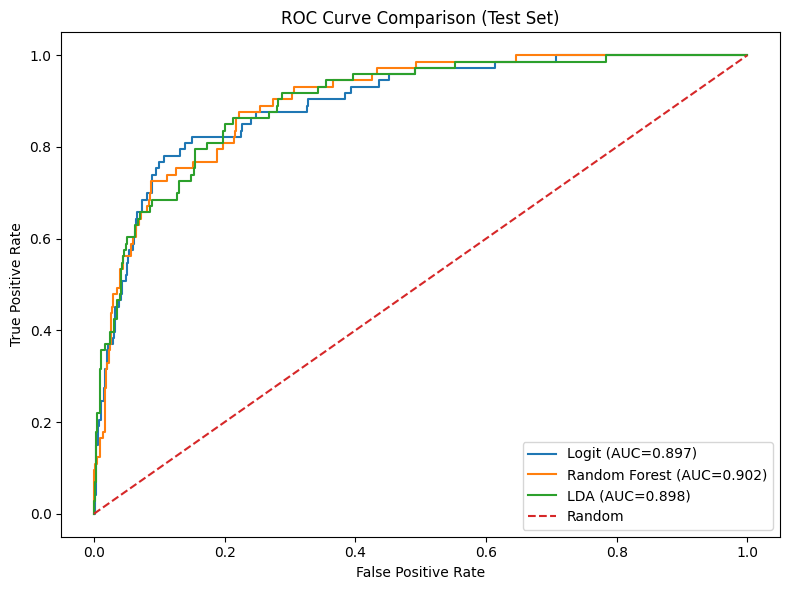

In [69]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import numpy as np

# --- Ensure LDA probabilities exist (using your LDA pipeline) ---
# (Run this after lda_model.fit(X_train, y_train) has executed successfully)
lda_proba = lda_model.predict_proba(X_test)[:, 1]
lda_pred  = (lda_proba >= 0.5).astype(int)

# --- Defensive checks to avoid NameError ---
required_vars = ["test_proba", "rf_proba", "lda_proba"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(f"Missing variables: {missing}. Make sure you ran Logit/RF/LDA prediction cells first.")

# --- AUC scores ---
logit_auc = roc_auc_score(y_test, test_proba)
rf_auc    = roc_auc_score(y_test, rf_proba)
lda_auc   = roc_auc_score(y_test, lda_proba)

print(f"Logit AUC: {logit_auc:.3f}")
print(f"RF AUC:    {rf_auc:.3f}")
print(f"LDA AUC:   {lda_auc:.3f}")

# --- ROC Curves ---
logit_fpr, logit_tpr, _ = roc_curve(y_test, test_proba)
rf_fpr, rf_tpr, _       = roc_curve(y_test, rf_proba)
lda_fpr, lda_tpr, _     = roc_curve(y_test, lda_proba)

plt.figure(figsize=(8, 6))
plt.plot(logit_fpr, logit_tpr, label=f"Logit (AUC={logit_auc:.3f})")
plt.plot(rf_fpr, rf_tpr, label=f"Random Forest (AUC={rf_auc:.3f})")
plt.plot(lda_fpr, lda_tpr, label=f"LDA (AUC={lda_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison (Test Set)")
plt.legend()
plt.tight_layout()
plt


## 12. Save Outputs for the Business Report (summary + odds ratios + ROC image)

In [73]:
import os
print(os.getcwd())


/content


In [77]:
import os

print("Exists:", os.path.exists("/content/outputs"))
print("Is directory:", os.path.isdir("/content/outputs"))
print("Is file:", os.path.isfile("/content/outputs"))


Exists: True
Is directory: False
Is file: True


In [78]:
#remove the existing directory
os.remove("/content/outputs")


In [79]:
# re create the directory
os.makedirs("/content/outputs", exist_ok=True)


In [80]:
#verify its created again
print(os.path.isdir("/content/outputs"))  # should be True


True


In [81]:
#saving the model performance summary
summary.to_csv(f"{OUT_DIR}/model_performance_summary.csv", index=False)


In [82]:
#saving the logistic regression odds ratio
or_table.to_csv(f"{OUT_DIR}/logit_odds_ratios.csv", index=True)


In [83]:
#saving the ROC curve image
plt.savefig(f"{OUT_DIR}/roc_comparison.png", dpi=200, bbox_inches="tight")


<Figure size 640x480 with 0 Axes>

In [84]:
! jupyter nbconvert --to html /content/Financial_Risk_Assessment.ipynb

[NbConvertApp] Converting notebook /content/Financial_Risk_Assessment.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 9 image(s).
[NbConvertApp] Writing 1120782 bytes to /content/Financial_Risk_Assessment.html
